# 02 Estimation and hypothesis tests: Bangladesh food prices

This notebook covers the BUS173 topics on confidence intervals and hypothesis tests. Each test follows the same steps: state H0 and H1, check the assumptions, choose a test that fits them, report an effect size with a confidence interval, then say in plain words what the result means.

Most of the data are monthly time series. Monthly price changes are autocorrelated, so the textbook tests, which assume independent observations, give standard errors that are too small. Where that matters, the notebook also reports a version that allows for it: Newey-West (HAC) standard errors or a moving block bootstrap.

Data: WFP retail prices (`national_prices`, `division_prices`, `prices_monthly`), the official food CPI and exchange rate (`covariates_monthly`), built by `src/clean.py`. Helpers are in `src/tests_stats.py`. All results go to `outputs/tables/tests_02_*.csv`; README numbers go to `outputs/tables/key_facts_tests.csv`.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from plot_utils import *
import tests_stats as ts
set_style()
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)

nat = ts.national_wide()
cov = ts.covariates()
prices = pd.read_parquet(PROC / "prices_monthly.parquet")
retail = prices[(prices.pricetype == "Retail") & ~prices.outlier]
LONG = ts.LONG
R, facts = [], []
def fact(name, value, how):
    facts.append({"fact": name, "value": value, "how_computed": how})
    print(f"{name}: {value}")

## 1. Confidence intervals

### 1a. Mean retail price across markets in one month

For each of the 11 core items, take the latest month in which at least 20 markets report it. The markets are a cross-section, so treating them as independent draws is reasonable (nearby markets share supply, which still makes the intervals a little too narrow). The t-interval assumes the sample mean is close to normal. With 20 to 90 markets that holds unless prices are very skewed, so a percentile bootstrap of the mean (4,000 resamples) is shown as a check, plus a bootstrap interval for the median, which is less affected by one expensive market.

In [2]:
core = retail[retail.item.notna() & (retail.market_level == "market")]
rows = []
for it in ITEM_LABEL:
    x = core[core.item == it]
    cnt = x.groupby("date").market.nunique()
    month = cnt[cnt >= 20].index.max()
    v = x[x.date == month].groupby("market").price_bdt.mean().values
    m, lo, hi = ts.t_ci(v)
    _, blo, bhi = ts.boot_ci(v)
    med, mlo, mhi = ts.boot_ci(v, stat=np.median)
    rows.append(dict(item=it, month=str(month.date())[:7], n_markets=len(v), mean=m, t_low=lo, t_high=hi,
                     boot_low=blo, boot_high=bhi, median=med, med_low=mlo, med_high=mhi,
                     skew=stats.skew(v), shapiro_p=stats.shapiro(v).pvalue,
                     t_halfwidth_pct=100 * (hi - lo) / 2 / m))
ci_price = pd.DataFrame(rows)
ci_price.to_csv(TAB / "tests_02_ci_prices.csv", index=False)
ci_price.round(2)

,item,month,n_markets,mean,t_low,t_high,boot_low,boot_high,median,med_low,med_high,skew,shapiro_p,t_halfwidth_pct
0,rice_coarse,2026-07,46,49.31,48.11,50.50,48.21,50.47,49.00,47.65,50.30,0.83,0.09,2.42
1,atta,2026-08,73,56.03,55.29,56.78,55.33,56.78,55.80,54.50,57.00,0.18,0.26,1.33
2,lentil_masur,2026-07,75,94.07,91.93,96.20,92.05,96.19,92.50,89.00,94.00,1.84,0.00,2.27
3,palm_oil,2026-07,68,168.84,167.41,170.28,167.48,170.31,167.50,165.50,169.00,1.23,0.00,0.85
4,soybean_oil,2026-07,82,188.36,186.83,189.89,186.85,189.83,188.80,187.00,189.25,-1.56,0.00,0.81
5,sugar,2026-07,84,104.76,104.24,105.28,104.23,105.27,104.50,103.80,105.00,-0.08,0.01,0.50
6,egg,2026-07,87,10.69,10.57,10.81,10.58,10.81,10.60,10.50,10.80,1.11,0.00,1.15
7,chicken_broiler,2026-07,30,173.09,170.41,175.77,170.55,175.66,171.90,169.10,176.10,0.42,0.21,1.55
8,onion,2026-01,26,63.38,60.32,66.44,60.52,66.09,64.24,59.43,67.41,-0.49,0.54,4.83
9,potato,2024-12,27,66.17,64.49,67.84,64.64,67.81,65.19,63.55,68.45,0.31,0.80,2.53


In [3]:
fact("ci_price_items", len(ci_price), "Core items with a cross-market CI (latest month with >= 20 markets)")
fact("ci_price_max_halfwidth_pct", round(ci_price.t_halfwidth_pct.max(), 1), "Widest 95% t-interval half-width, % of mean")
fact("ci_price_max_halfwidth_item", ci_price.loc[ci_price.t_halfwidth_pct.idxmax(), "item"], "Item with the widest interval")
fact("ci_price_median_halfwidth_pct", round(ci_price.t_halfwidth_pct.median(), 1), "Median half-width across items, % of mean")
d = (ci_price[["boot_low", "boot_high"]].values - ci_price[["t_low", "t_high"]].values) / ci_price[["mean"]].values * 100
fact("ci_price_max_t_vs_boot_diff_pct", round(np.abs(d).max(), 2), "Largest gap between t and bootstrap limits, % of mean")

ci_price_items: 11
ci_price_max_halfwidth_pct: 4.8
ci_price_max_halfwidth_item: onion
ci_price_median_halfwidth_pct: 1.6
ci_price_max_t_vs_boot_diff_pct: 0.55


### 1b. Mean year-on-year inflation of each staple, 2007 to 2026

Here the observations are monthly 12-month log changes of the national price. They overlap: two neighbouring months share 11 of their 12 months, so the lag-1 autocorrelation is above 0.9. A t-interval that treats the 230 months as independent is far too narrow. Three alternatives are compared:

- iid bootstrap: resamples single months, so it has the same problem as the t-interval;
- moving block bootstrap with 24-month blocks, which keeps runs of months together;
- Newey-West (HAC) interval with 18 lags, which widens the standard error for the autocorrelation.

The honest interval is the block or HAC one.

In [4]:
yoy = ts.dlog(nat[LONG], 12).loc["2007":]
rows = []
for it in LONG:
    x = yoy[it].dropna().values
    m, lo, hi = ts.t_ci(x)
    _, blo, bhi = ts.boot_ci(x)
    _, bblo, bbhi = ts.boot_ci(x, block=24)
    _, hlo, hhi, _, _ = ts.hac_mean(x, lags=18)
    rows.append(dict(item=it, n_months=len(x), mean_yoy=m, rho1=ts.lag1_autocorr(x), t_low=lo, t_high=hi,
                     iid_boot_low=blo, iid_boot_high=bhi, block_boot_low=bblo, block_boot_high=bbhi,
                     hac_low=hlo, hac_high=hhi, width_ratio_hac_vs_t=(hhi - hlo) / (hi - lo)))
ci_yoy = pd.DataFrame(rows)
ci_yoy.to_csv(TAB / "tests_02_ci_inflation.csv", index=False)
ci_yoy.round(2)

,item,n_months,mean_yoy,rho1,t_low,t_high,iid_boot_low,iid_boot_high,block_boot_low,block_boot_high,hac_low,hac_high,width_ratio_hac_vs_t
0,rice_coarse,227,5.85,0.96,3.02,8.68,3.07,8.62,-1.26,11.04,-1.55,13.25,2.61
1,atta,228,4.50,0.97,1.59,7.41,1.65,7.37,-4.42,10.66,-4.09,13.09,2.96
2,lentil_masur,231,3.33,0.96,1.21,5.45,1.18,5.44,-4.64,10.44,-3.83,10.50,3.38
3,palm_oil,215,4.32,0.96,1.57,7.08,1.53,7.10,-3.67,13.29,-4.02,12.67,3.02


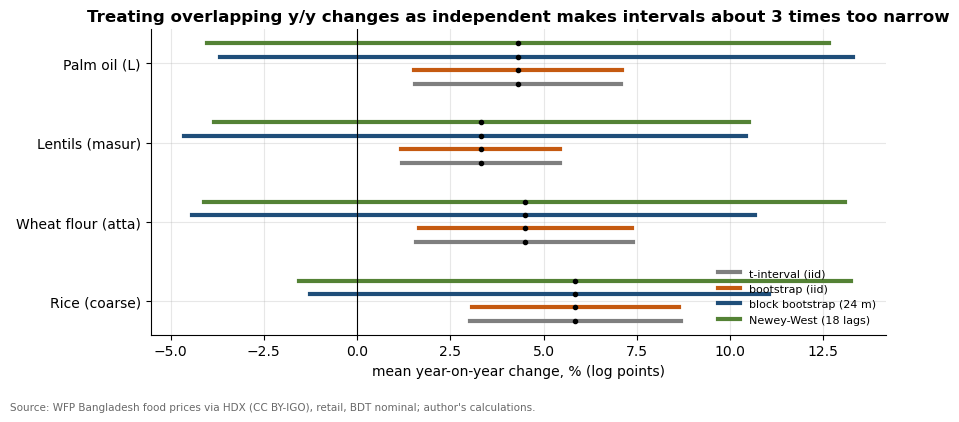

yoy_mean_rice_coarse: 5.85
yoy_hac_ci_rice_coarse: -1.6 to 13.3
yoy_mean_atta: 4.5
yoy_hac_ci_atta: -4.1 to 13.1
yoy_mean_lentil_masur: 3.33
yoy_hac_ci_lentil_masur: -3.8 to 10.5
yoy_mean_palm_oil: 4.32
yoy_hac_ci_palm_oil: -4.0 to 12.7
yoy_width_ratio_hac_vs_t_median: 2.99


In [5]:
fig, ax = plt.subplots(figsize=(9, 4.2))
methods = [("t", "t-interval (iid)", GREY), ("iid_boot", "bootstrap (iid)", ORANGE),
           ("block_boot", "block bootstrap (24 m)", BLUE), ("hac", "Newey-West (18 lags)", GREEN)]
for i, r in ci_yoy.iterrows():
    for j, (k, lab, col) in enumerate(methods):
        y = i + (j - 1.5) * 0.17
        ax.plot([r[f"{k}_low"], r[f"{k}_high"]], [y, y], color=col, lw=3, label=lab if i == 0 else None)
        ax.plot(r.mean_yoy, y, "o", color="black", ms=3)
ax.set_yticks(range(len(ci_yoy))); ax.set_yticklabels([ITEM_LABEL[i] for i in ci_yoy.item])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("mean year-on-year change, % (log points)")
ax.set_title("Treating overlapping y/y changes as independent makes intervals about 3 times too narrow")
ax.legend(loc="lower right", fontsize=8)
save(fig, "fig08_ci_inflation"); plt.show()
for _, r in ci_yoy.iterrows():
    fact(f"yoy_mean_{r['item']}", round(r.mean_yoy, 2), "Mean y/y log change, %, 2007 to latest")
    fact(f"yoy_hac_ci_{r['item']}", f"{r.hac_low:.1f} to {r.hac_high:.1f}", "95% Newey-West CI, 18 lags")
fact("yoy_width_ratio_hac_vs_t_median", round(ci_yoy.width_ratio_hac_vs_t.median(), 2), "Median ratio of HAC to naive t-interval width")

## 2. Dhaka against the other divisions

**Question.** Are staple prices in Dhaka division different from those in each other division?

- H0: the mean monthly log price gap, Dhaka minus division k, is zero.
- H1: it is not zero (two-sided).

**Design.** The two prices are measured in the same month, so they are paired. Pairing removes the common trend and the national shocks that hit every division. The paired t-test is a one-sample t-test on the gaps.

**Assumptions.** (1) The gaps are close to normal, or n is large: n is 190 to 243 months, so the mean is close to normal. (2) The gaps are independent across months: this fails, because a gap that opens in one month tends to persist. The Wilcoxon signed-rank test drops the normality assumption but keeps independence. So the decision rests on the Newey-West version, which keeps the paired design and corrects the standard error. Effect size: mean gap in percent, and Cohen's d_z (mean gap / SD of gaps).

In [6]:
rows_gap, gap_tbl = [], []
for it in LONG:
    w = ts.division_wide(it)
    for dv in [c for c in w.columns if c != "Dhaka"]:
        g = (100 * np.log(w["Dhaka"] / w[dv])).dropna()
        n = len(g)
        t = stats.ttest_1samp(g, 0)
        m, lo, hi = ts.t_ci(g)
        wil = stats.wilcoxon(g)
        hm, hlo, hhi, hz, hp = ts.hac_mean(g)
        rho = ts.lag1_autocorr(g)
        lab = f"{it}: Dhaka - {dv}"
        concl = ("Dhaka dearer" if hm > 0 else "Dhaka cheaper") + (" (HAC p < 0.05)" if hp < 0.05 else ", not significant once autocorrelation is allowed for")
        R += [ts.row("2 Dhaka vs division", "Paired t", lab, n, t.statistic, n - 1, t.pvalue, "Cohen's d_z", ts.cohen_dz(g), (lo, hi), f"mean gap {m:.2f}%; CI is for the mean gap"),
              ts.row("2 Dhaka vs division", "Wilcoxon signed-rank", lab, n, wil.statistic, np.nan, wil.pvalue, "median gap %", np.median(g)),
              ts.row("2 Dhaka vs division", "Paired t, Newey-West SE", lab, n, hz, np.nan, hp, "mean gap %", hm, (hlo, hhi), concl)]
        gap_tbl.append(dict(item=it, division=dv, n=n, mean_gap=m, rho1=rho, p_t=t.pvalue, p_wilcoxon=wil.pvalue, p_hac=hp, hac_low=hlo, hac_high=hhi))
gap_tbl = pd.DataFrame(gap_tbl)
gap_tbl.round(3)

,item,division,n,mean_gap,rho1,p_t,p_wilcoxon,p_hac,hac_low,hac_high
0,rice_coarse,Barishal,222,-1.225,0.565,0.002,0.001,0.047,-2.434,-0.015
1,rice_coarse,Chattogram,237,-0.419,0.652,0.353,0.612,0.585,-1.924,1.086
2,rice_coarse,Khulna,225,3.261,0.406,0.000,0.000,0.000,2.450,4.073
3,rice_coarse,Rajshahi,229,5.271,0.637,0.000,0.000,0.000,4.357,6.185
4,rice_coarse,Sylhet,190,2.718,0.564,0.000,0.000,0.000,1.382,4.053
5,atta,Barishal,232,-4.057,0.758,0.000,0.000,0.000,-5.142,-2.973
6,atta,Chattogram,241,-5.744,0.753,0.000,0.000,0.000,-6.711,-4.777
7,atta,Khulna,243,-2.850,0.893,0.000,0.000,0.000,-4.042,-1.657
8,atta,Rajshahi,238,-1.823,0.899,0.000,0.000,0.001,-2.914,-0.732
9,atta,Sylhet,232,-7.106,0.768,0.000,0.000,0.000,-8.184,-6.028


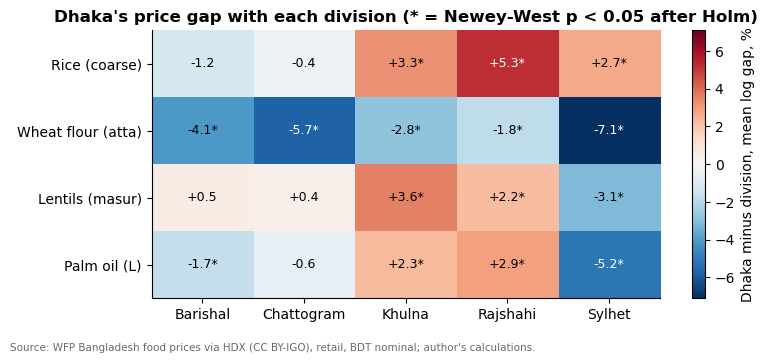

dhaka_pairs_tested: 20
dhaka_pairs_sig_naive_t: 17
dhaka_pairs_sig_hac_holm: 15
dhaka_gap_abs_max_pct: 7.1
dhaka_gap_median_rho1: 0.65


In [7]:
gap_tbl["p_hac_holm"] = ts.multipletests(gap_tbl.p_hac, method="holm")[1]
piv = gap_tbl.pivot(index="item", columns="division", values="mean_gap").reindex(LONG)
sig = gap_tbl.pivot(index="item", columns="division", values="p_hac_holm").reindex(LONG)
fig, ax = plt.subplots(figsize=(8, 3.6))
lim = np.nanmax(np.abs(piv.values))
im = ax.imshow(piv.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.grid(False)
ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns)
ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels([ITEM_LABEL[i] for i in piv.index])
for (i, j), v in np.ndenumerate(piv.values):
    star = "*" if sig.values[i, j] < 0.05 else ""
    ax.text(j, i, f"{v:+.1f}{star}", ha="center", va="center", fontsize=9, color="white" if abs(v) > 0.6 * lim else "black")
fig.colorbar(im, ax=ax, label="Dhaka minus division, mean log gap, %")
ax.set_title("Dhaka's price gap with each division (* = Newey-West p < 0.05 after Holm)")
save(fig, "fig09_dhaka_gap"); plt.show()
fact("dhaka_pairs_tested", len(gap_tbl), "Item x division pairs")
fact("dhaka_pairs_sig_naive_t", int((gap_tbl.p_t < 0.05).sum()), "Pairs with paired-t p < 0.05 (no correction)")
fact("dhaka_pairs_sig_hac_holm", int((gap_tbl.p_hac_holm < 0.05).sum()), "Pairs with Newey-West p < 0.05 after Holm")
fact("dhaka_gap_abs_max_pct", round(gap_tbl.mean_gap.abs().max(), 1), "Largest |mean gap|, %")
fact("dhaka_gap_median_rho1", round(gap_tbl.rho1.median(), 2), "Median lag-1 autocorrelation of the monthly gap")

## 3. Ramadan

**Question.** Are prices higher in the Ramadan month than in the two months before it? Demand for lentils, chickpeas, edible oil, sugar and onions rises during Ramadan, and traders are often accused of raising prices ahead of it.

The Ramadan month is the calendar month with at least half of its days in Ramadan (`ramadan_month` in `covariates_monthly`). Because the Islamic calendar is 11 days shorter, Ramadan moved from October (2006) to March (2026), so the Ramadan effect is not the same thing as a fixed calendar season.

### 3a. Long-history items, paired by year (2007 to 2026)

For each year, the Ramadan-month log price is compared with the mean log price of the two months before. Lentils and palm oil are the Ramadan items with 20 years of data. Rice and wheat flour are placebos: their demand does not rise much in Ramadan.

- H0: mean over years of [log p(Ramadan) - mean log p(two months before)] = 0.
- H1: it is greater than zero (one-sided, because the claim is that prices rise).

One pair per year means the pairs are about a year apart, so they are close to independent. Prices drift up over time anyway, so the expected change over 1.5 months is not zero. The second test subtracts each item's average 1.5-month drift computed over all months.

In [8]:
ram = cov.ramadan_month.fillna(False).astype(bool)
ram_months = ram[ram].index
lp = np.log(nat)
def ramadan_pairs(series):
    rows = []
    for r in ram_months:
        pre = [r - pd.DateOffset(months=k) for k in (1, 2)]
        if r in series.index and all(p in series.index for p in pre):
            a, b = series.get(r), series.reindex(pre).mean()
            if np.isfinite(a) and np.isfinite(b) and series.reindex(pre).notna().all():
                rows.append((r.year, 100 * (a - b)))
    return pd.DataFrame(rows, columns=["year", "diff"]).set_index("year")["diff"]

ram_rows = []
for it in LONG:
    s = lp[it].dropna()
    d = ramadan_pairs(s)
    drift = (100 * (s - (s.shift(1) + s.shift(2)) / 2)).dropna().mean()
    adj = d - drift
    n = len(d)
    t = stats.ttest_1samp(d, 0, alternative="greater")
    ta = stats.ttest_1samp(adj, 0, alternative="greater")
    w = stats.wilcoxon(adj, alternative="greater")
    m, lo, hi = ts.t_ci(d); ma, alo, ahi = ts.t_ci(adj)
    sh = stats.shapiro(adj).pvalue
    R += [ts.row("3 Ramadan", "Paired t, one-sided", f"{it}: Ramadan vs 2 months before", n, t.statistic, n - 1, t.pvalue, "mean diff %", m, (lo, hi), f"Shapiro p = {sh:.2f} for the adjusted differences"),
          ts.row("3 Ramadan", "Paired t, drift-adjusted, one-sided", f"{it}: Ramadan vs 2 months before", n, ta.statistic, n - 1, ta.pvalue, "mean excess diff %", ma, (alo, ahi),
                 "higher in Ramadan" if ta.pvalue < 0.05 else "no evidence of a Ramadan rise beyond normal drift"),
          ts.row("3 Ramadan", "Wilcoxon signed-rank, drift-adjusted", f"{it}: Ramadan vs 2 months before", n, w.statistic, np.nan, w.pvalue, "median excess diff %", np.median(adj))]
    ram_rows.append(dict(item=it, group="long (by year)", n=n, mean=ma, low=alo, high=ahi, p=ta.pvalue, drift=drift))
pd.DataFrame(ram_rows).round(3)

,item,group,n,mean,low,high,p,drift
0,rice_coarse,long (by year),19,-0.350,-1.842,1.142,0.686,0.630
1,atta,long (by year),20,-0.379,-1.697,0.939,0.723,0.610
2,lentil_masur,long (by year),20,0.517,-1.038,2.073,0.247,0.436
3,palm_oil,long (by year),20,-1.521,-4.219,1.177,0.874,0.704


### 3b. Items priced only since 2024, paired by market

Sugar, onion, soybean oil, chickpeas, eggs and chicken are only priced from 2024, which gives two usable Ramadans (March 2025 and March 2026; March 2024 has no data for January). Here each pair is one market in one year: the Ramadan-month price against the mean of January and February in the same market. There are many pairs, but they are not independent: all markets share the same national shocks in the same two springs. A significant result therefore says that prices rose between Jan-Feb and March in 2025 and 2026, which could be Ramadan or anything else that happened in those months. Read these as descriptive. The p-values use a market-clustered standard error (OLS on a constant, clustered by market) as well as the Wilcoxon test.

In [9]:
short_items = {"sugar": "sugar", "onion": "onion", "soybean_oil": "soybean_oil", "chicken_broiler": "chicken_broiler",
               "egg": "egg", "chickpea": None, "lentil_masur": "lentil_masur", "palm_oil": "palm_oil"}
mk = retail[(retail.date >= "2024-01-01") & (retail.market_level == "market")].copy()
mk.loc[mk.commodity == "Chickpeas", "item"] = "chickpea"
mk = mk[mk.item.isin(list(short_items))]
mp = mk.groupby(["item", "market", "date"]).price_bdt.mean()
short_rows = []
for it in short_items:
    pairs = []
    for r in [m for m in ram_months if m >= pd.Timestamp("2024-01-01")]:
        pre = [r - pd.DateOffset(months=k) for k in (1, 2)]
        x = mp.loc[it].unstack("date").reindex(columns=[r] + pre)
        x = x.dropna()
        for mkt, v in x.iterrows():
            pairs.append((mkt, r.year, 100 * (np.log(v[r]) - np.log(v[pre]).mean())))
    d = pd.DataFrame(pairs, columns=["market", "year", "diff"])
    if len(d) < 10:
        print(it, "too few pairs:", len(d)); continue
    fit = sm.OLS(d["diff"], np.ones(len(d))).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(d.market)[0]})
    lo, hi = fit.conf_int().iloc[0]
    w = stats.wilcoxon(d["diff"], alternative="greater")
    by_year = d.groupby("year")["diff"].mean().round(2).to_dict()
    R += [ts.row("3 Ramadan (2024-26 markets)", "Mean diff, market-clustered SE", f"{it}: Ramadan vs Jan-Feb", len(d), fit.tvalues.iloc[0], d.market.nunique() - 1, fit.pvalues.iloc[0] / 2 if fit.params.iloc[0] > 0 else 1 - fit.pvalues.iloc[0] / 2,
                    "mean diff %", fit.params.iloc[0], (lo, hi), f"by year: {by_year}; only {d.year.nunique()} Ramadans, descriptive"),
          ts.row("3 Ramadan (2024-26 markets)", "Wilcoxon signed-rank, one-sided", f"{it}: Ramadan vs Jan-Feb", len(d), w.statistic, np.nan, w.pvalue, "median diff %", d["diff"].median())]
    short_rows.append(dict(item=it, group="2025-26 (by market)", n=len(d), mean=fit.params.iloc[0], low=lo, high=hi, p=fit.pvalues.iloc[0], years=by_year))
pd.DataFrame(short_rows).round(3)

chickpea too few pairs: 4


,item,group,n,mean,low,high,p,years
0,sugar,2025-26 (by market),54,-1.982,-2.407,-1.558,0.000,"{2025: -2.12, 2026: -0.32}"
1,onion,2025-26 (by market),25,-6.346,-9.513,-3.179,0.000,"{2025: -5.18, 2026: -12.46}"
2,soybean_oil,2025-26 (by market),60,-2.026,-2.845,-1.207,0.000,"{2025: -1.96, 2026: -2.93}"
3,chicken_broiler,2025-26 (by market),33,1.127,-0.474,2.729,0.168,"{2025: 0.46, 2026: 22.37}"
4,egg,2025-26 (by market),58,-7.252,-8.112,-6.392,0.000,{2025: -7.25}
5,lentil_masur,2025-26 (by market),111,-0.483,-1.233,0.267,0.207,"{2024: 0.04, 2025: -1.15, 2026: -1.62}"
6,palm_oil,2025-26 (by market),150,-0.281,-0.627,0.064,0.110,"{2024: 0.05, 2025: -2.72, 2026: 1.87}"


### 3c. The linear model version

The same question as a regression on all months, not just the Ramadan window:

d log p(t) = a + b1 Ramadan(t) + b2 PreRamadan(t) + calendar-month dummies + e(t)

`PreRamadan` marks the month before the Ramadan month, when households and traders stock up. Calendar-month dummies take out the normal seasonal pattern (for example the rice harvest), which Ramadan moves through over the years. The errors are autocorrelated, so the standard errors are Newey-West with the rule-of-thumb lag. H0: b1 = 0 (and separately b2 = 0).

In [10]:
m_m = ts.dlog(nat[LONG]).loc["2007":]
X0 = pd.DataFrame({"ramadan": ram.astype(float), "pre_ramadan": ram.shift(-1).fillna(False).astype(float)}, index=cov.index)
reg_rows = []
for it in LONG:
    y = m_m[it].dropna()
    X = X0.reindex(y.index)
    X = X.join(pd.get_dummies(y.index.month, prefix="m", drop_first=True, dtype=float).set_index(y.index))
    fit = ts.hac_ols(y, sm.add_constant(X))
    for v in ["ramadan", "pre_ramadan"]:
        lo, hi = fit.conf_int().loc[v]
        R.append(ts.row("3 Ramadan (regression)", f"OLS + month dummies, Newey-West, {v}", f"{it}: monthly % change", int(fit.nobs), fit.tvalues[v], fit.df_resid, fit.pvalues[v],
                        "coefficient (pp per month)", fit.params[v], (lo, hi), "significant" if fit.pvalues[v] < 0.05 else "not significant"))
        reg_rows.append(dict(item=it, term=v, coef=fit.params[v], low=lo, high=hi, p=fit.pvalues[v], n=int(fit.nobs), lags=ts.nw_lags(int(fit.nobs))))
reg_tbl = pd.DataFrame(reg_rows); reg_tbl.round(3)

,item,term,coef,low,high,p,n,lags
0,rice_coarse,ramadan,-0.629,-1.826,0.568,0.303,226,4
1,rice_coarse,pre_ramadan,0.053,-1.545,1.651,0.948,226,4
2,atta,ramadan,-0.092,-0.980,0.796,0.839,229,4
3,atta,pre_ramadan,0.331,-0.885,1.547,0.594,229,4
4,lentil_masur,ramadan,0.030,-1.122,1.183,0.959,229,4
5,lentil_masur,pre_ramadan,1.908,-0.305,4.121,0.091,229,4
6,palm_oil,ramadan,-1.941,-3.961,0.078,0.060,224,4
7,palm_oil,pre_ramadan,0.162,-1.453,1.777,0.844,224,4


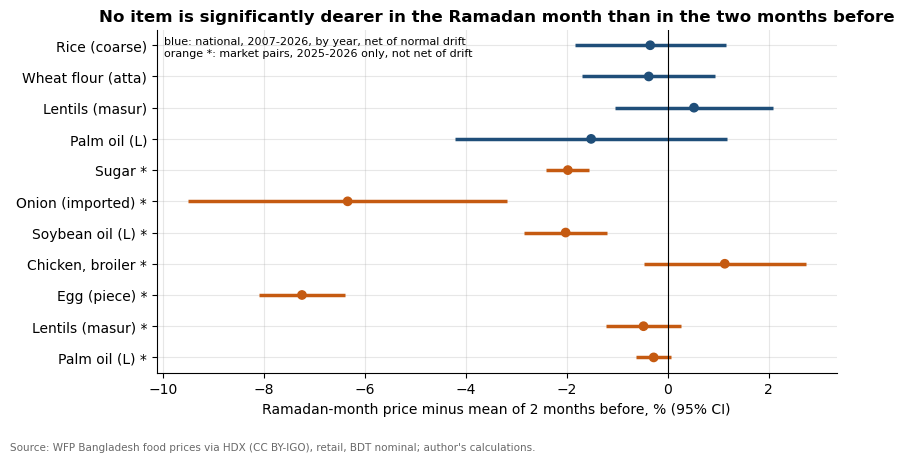

ramadan_excess_rice_coarse: -0.35
ramadan_excess_p_rice_coarse: 0.686
ramadan_excess_atta: -0.38
ramadan_excess_p_atta: 0.723
ramadan_excess_lentil_masur: 0.52
ramadan_excess_p_lentil_masur: 0.247
ramadan_excess_palm_oil: -1.52
ramadan_excess_p_palm_oil: 0.874
ramadan_market_sugar: -1.98
ramadan_market_onion: -6.35
ramadan_market_soybean_oil: -2.03
ramadan_market_chicken_broiler: 1.13
ramadan_market_egg: -7.25
ramadan_market_lentil_masur: -0.48
ramadan_market_palm_oil: -0.28
ramadan_reg_ramadan_rice_coarse: -0.63
ramadan_reg_pre_ramadan_rice_coarse: 0.05
ramadan_reg_ramadan_atta: -0.09
ramadan_reg_pre_ramadan_atta: 0.33
ramadan_reg_ramadan_lentil_masur: 0.03
ramadan_reg_pre_ramadan_lentil_masur: 1.91
ramadan_reg_ramadan_palm_oil: -1.94
ramadan_reg_pre_ramadan_palm_oil: 0.16


In [11]:
rr = pd.concat([pd.DataFrame(ram_rows), pd.DataFrame(short_rows)], ignore_index=True)
fig, ax = plt.subplots(figsize=(8.5, 4.6))
cols = [BLUE if g.startswith("long") else ORANGE for g in rr.group]
y = np.arange(len(rr))[::-1]
ax.errorbar(rr["mean"], y, xerr=[rr["mean"] - rr.low, rr.high - rr["mean"]], fmt="none", ecolor=cols, elinewidth=2.5)
ax.scatter(rr["mean"], y, color=cols, zorder=3)
ax.set_yticks(y); ax.set_yticklabels([("Chickpeas" if i == "chickpea" else ITEM_LABEL[i]) + ("" if g.startswith("long") else " *") for i, g in zip(rr.item, rr.group)])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Ramadan-month price minus mean of 2 months before, % (95% CI)")
ax.set_title("No item is significantly dearer in the Ramadan month than in the two months before")
ax.text(0.01, 0.98, "blue: national, 2007-2026, by year, net of normal drift\norange *: market pairs, 2025-2026 only, not net of drift",
        transform=ax.transAxes, ha="left", va="top", fontsize=8)
save(fig, "fig10_ramadan"); plt.show()
for r in ram_rows:
    fact(f"ramadan_excess_{r['item']}", round(r["mean"], 2), "Mean Ramadan-vs-2-months-before log diff net of drift, %, 2007-2026")
    fact(f"ramadan_excess_p_{r['item']}", round(r["p"], 3), "One-sided paired t p-value")
for r in short_rows:
    fact(f"ramadan_market_{r['item']}", round(r["mean"], 2), "Mean market-level Ramadan-vs-Jan-Feb diff, %, 2025-2026")
for r in reg_rows:
    fact(f"ramadan_reg_{r['term']}_{r['item']}", round(r["coef"], 2), f"Newey-West OLS coefficient, pp per month (p = {r['p']:.3f})")

## 4. Differences across divisions

**Question.** Do the six legacy divisions (the six WFP reported before 2020) have different price levels, and different inflation?

To remove the common trend, each division's price is expressed relative to the national price in the same month: 100 x log(division / national). These relative prices are then averaged by calendar year, so each division contributes one value per year (about 20). Yearly averages are much less autocorrelated than months, but a division that is dear one year tends to be dear the next, so p-values are still somewhat optimistic.

- H0: the mean relative price is the same in all six divisions.
- H1: at least one division differs.

**Assumptions for one-way ANOVA.** Normal errors within groups (checked with Shapiro on residuals), equal variances (Levene, median-centred), independent observations (see above). If Levene rejects, Welch's ANOVA is used; Kruskal-Wallis is the rank-based check. Tukey HSD says which pairs differ. Effect size: eta-squared (share of variance explained by division).

The second test applies the same steps to yearly inflation: 100 x log of a division's annual mean price over the previous year's.

In [12]:
dp = pd.read_parquet(PROC / "division_prices.parquet")
dp = dp[dp.item.isin(LONG) & (dp.date >= "2007-01-01")]
dp = dp.merge(pd.read_parquet(PROC / "national_prices.parquet")[["date", "item", "price_bdt"]].rename(columns={"price_bdt": "nat"}), on=["date", "item"])
dp["rel"] = 100 * np.log(dp.price_bdt / dp.nat)
dp["year"] = dp.date.dt.year
ann = dp.groupby(["item", "division", "year"]).agg(rel=("rel", "mean"), price=("price_bdt", "mean"), months=("rel", "size")).reset_index()
ann = ann[ann.months >= 6]
ann["infl"] = ann.sort_values("year").groupby(["item", "division"]).price.transform(lambda s: 100 * np.log(s / s.shift(1)))
ann.loc[ann.sort_values("year").groupby(["item", "division"]).year.diff().ne(1).reindex(ann.index).fillna(True), "infl"] = np.nan

tukey_all, anova_rows = [], []
for var, label in [("rel", "price level relative to national"), ("infl", "annual inflation")]:
    for it in LONG:
        a = ann[(ann.item == it)].dropna(subset=[var])
        groups = [g[var].values for _, g in a.groupby("division")]
        F = stats.f_oneway(*groups)
        lev = stats.levene(*groups, center="median")
        wel = anova_oneway(groups, use_var="unequal")
        kw = stats.kruskal(*groups)
        grand = a[var].mean()
        ssb = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
        eta2 = ssb / ((a[var] - grand) ** 2).sum()
        resid = np.concatenate([g - g.mean() for g in groups])
        sh = stats.shapiro(resid).pvalue
        k, n = len(groups), len(a)
        sec = f"4 Divisions: {label}"
        main_p = wel.pvalue if lev.pvalue < 0.05 else F.pvalue
        R += [ts.row(sec, "Levene (median)", it, n, lev.statistic, f"{k-1}, {n-k}", lev.pvalue, "", np.nan, conclusion="variances differ" if lev.pvalue < 0.05 else "equal variances not rejected"),
              ts.row(sec, "One-way ANOVA", it, n, F.statistic, f"{k-1}, {n-k}", F.pvalue, "eta squared", eta2, conclusion=f"Shapiro p on residuals = {sh:.3f}"),
              ts.row(sec, "Welch ANOVA", it, n, wel.statistic, f"{k-1}, {wel.df[1]:.1f}", wel.pvalue, "eta squared", eta2,
                     conclusion=("divisions differ" if main_p < 0.05 else "no evidence divisions differ") + (" (Welch used, Levene rejects)" if lev.pvalue < 0.05 else " (classic ANOVA used)")),
              ts.row(sec, "Kruskal-Wallis", it, n, kw.statistic, k - 1, kw.pvalue, "", np.nan)]
        anova_rows.append(dict(variable=var, item=it, n=n, F=F.statistic, p_anova=F.pvalue, p_welch=wel.pvalue, p_levene=lev.pvalue, p_kw=kw.pvalue, eta2=eta2, shapiro_resid_p=sh))
        tk = pairwise_tukeyhsd(a[var], a.division)
        t = pd.DataFrame(tk._results_table.data[1:], columns=tk._results_table.data[0]).assign(item=it, variable=var)
        tukey_all.append(t)
anova_tbl = pd.DataFrame(anova_rows)
tukey = pd.concat(tukey_all, ignore_index=True)
tukey.to_csv(TAB / "tests_02_tukey.csv", index=False)
anova_tbl.round(3)

,variable,item,n,F,p_anova,p_welch,p_levene,p_kw,eta2,shapiro_resid_p
0,rel,rice_coarse,118,9.676,0.000,0.000,0.382,0.000,0.302,0.570
1,rel,atta,120,30.261,0.000,0.000,0.000,0.000,0.570,0.397
2,rel,lentil_masur,120,10.490,0.000,0.000,0.012,0.000,0.315,0.292
3,rel,palm_oil,115,46.492,0.000,0.000,0.112,0.000,0.681,0.361
4,infl,rice_coarse,111,0.036,0.999,0.999,0.993,0.999,0.002,0.015
5,infl,atta,114,0.001,1.000,1.000,1.000,1.000,0.000,0.000
6,infl,lentil_masur,114,0.004,1.000,1.000,0.957,1.000,0.000,0.180
7,infl,palm_oil,109,0.031,1.000,0.999,0.996,1.000,0.001,0.330


In [13]:
print("Tukey HSD pairs that differ (relative price level):")
tk_sig = tukey[(tukey.variable == "rel") & tukey.reject]
print(tk_sig[["item", "group1", "group2", "meandiff", "p-adj", "lower", "upper"]].round(3).to_string(index=False))
means = ann.groupby(["item", "division"]).rel.mean().unstack()
print("\nMean relative price, %:")
print(means.round(2))

Tukey HSD pairs that differ (relative price level):
        item     group1   group2  meandiff  p-adj  lower  upper
 rice_coarse   Barishal   Khulna    -4.314  0.004 -7.681 -0.948
 rice_coarse   Barishal Rajshahi    -6.233  0.000 -9.556 -2.909
 rice_coarse   Barishal   Sylhet    -4.236  0.005 -7.603 -0.869
 rice_coarse Chattogram   Khulna    -3.630  0.027 -6.997 -0.263
 rice_coarse Chattogram Rajshahi    -5.548  0.000 -8.871 -2.224
 rice_coarse Chattogram   Sylhet    -3.552  0.032 -6.919 -0.185
 rice_coarse      Dhaka   Khulna    -3.411  0.045 -6.778 -0.044
 rice_coarse      Dhaka Rajshahi    -5.329  0.000 -8.653 -2.006
        atta   Barishal    Dhaka    -4.067  0.000 -6.023 -2.112
        atta   Barishal Rajshahi    -2.207  0.017 -4.163 -0.252
        atta   Barishal   Sylhet     3.024  0.000  1.069  4.980
        atta Chattogram    Dhaka    -5.969  0.000 -7.925 -4.014
        atta Chattogram   Khulna    -3.031  0.000 -4.987 -1.076
        atta Chattogram Rajshahi    -4.109  0.000 -6

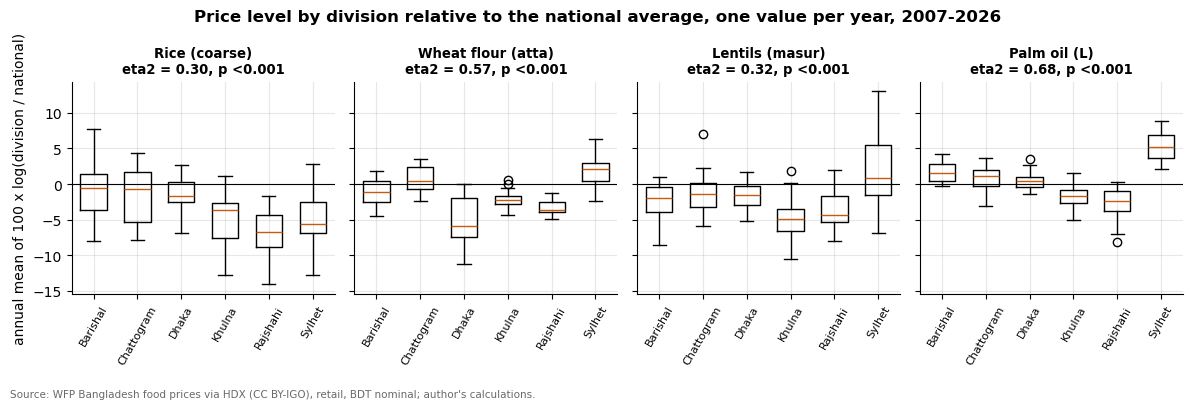

anova_rel_eta2_rice_coarse: 0.302
anova_rel_eta2_atta: 0.57
anova_rel_eta2_lentil_masur: 0.315
anova_rel_eta2_palm_oil: 0.681
anova_infl_eta2_rice_coarse: 0.002
anova_infl_eta2_atta: 0.0
anova_infl_eta2_lentil_masur: 0.0
anova_infl_eta2_palm_oil: 0.001
anova_infl_any_sig: 0
tukey_rel_sig_pairs: 36


In [14]:
divs = sorted(ann.division.unique())
fig, axes = plt.subplots(1, 4, figsize=(12, 4), sharey=True)
for ax, it in zip(axes, LONG):
    a = ann[ann.item == it]
    ax.boxplot([a[a.division == d].rel.values for d in divs], widths=0.6, medianprops=dict(color=ORANGE))
    ax.set_xticks(range(1, len(divs) + 1)); ax.set_xticklabels(divs, rotation=60, fontsize=8)
    ax.axhline(0, color="black", lw=0.8)
    r = anova_tbl[(anova_tbl.item == it) & (anova_tbl.variable == "rel")].iloc[0]
    p = r.p_welch if r.p_levene < 0.05 else r.p_anova
    ax.set_title(f"{ITEM_LABEL[it]}\neta2 = {r.eta2:.2f}, p {ts.fmt_p(p) if p < 0.001 else '= ' + ts.fmt_p(p)}", fontsize=9.5)
axes[0].set_ylabel("annual mean of 100 x log(division / national)")
fig.suptitle("Price level by division relative to the national average, one value per year, 2007-2026", fontweight="bold")
save(fig, "fig11_division_levels"); plt.show()
for _, r in anova_tbl.iterrows():
    fact(f"anova_{r['variable']}_eta2_{r['item']}", round(r.eta2, 3), "Eta squared, division effect, yearly data")
fact("anova_infl_any_sig", int(((anova_tbl.variable == "infl") & (anova_tbl[["p_anova", "p_welch"]].min(axis=1) < 0.05)).sum()), "Items whose annual inflation differs by division (p < 0.05)")
fact("tukey_rel_sig_pairs", int(len(tk_sig)), "Division pairs with different relative price level, Tukey HSD, all four items")

## 5. Before and after mid-2022

In 2022 world food and fuel prices jumped after the invasion of Ukraine, and the taka fell from about 86 to more than 110 per US dollar within a year, then to about 120. Imported staples (palm oil, lentils, wheat flour) should show it most.

- H0: mean monthly inflation is the same before (Jan 2007 to Jun 2022) and after (Jul 2022 onward).
- H1: it differs.

**Test choice.** The two periods have different lengths and probably different variances, so Welch's t-test (no equal-variance assumption) is the textbook choice, with Mann-Whitney as the rank check. Both assume independent months. Monthly changes have some autocorrelation, and the post period is short (about 48 months), so two corrected versions follow: a regression of the monthly change on a post-2022 dummy with Newey-West errors, and a moving block bootstrap (6-month blocks) of the difference in means. Effect size: Hedges' g and the difference in pp per month.

One more caveat: WFP moved from division-level to district-market prices in mid-2020. Both periods are measured as division medians, but the pre-2022 sample mixes the two designs.

In [15]:
fis = pd.read_parquet(PROC / "indices_long.parquet").set_index("date").asfreq("MS")
mm = ts.dlog(nat[LONG]).join(ts.dlog(fis[["fisher"]]).rename(columns={"fisher": "fisher_index"})).join(ts.dlog(cov[["bdt_per_usd"]]))
mm = mm.loc["2007-01":]
brk = pd.Timestamp("2022-07-01")
pp_rows = []
for c in LONG + ["fisher_index", "bdt_per_usd"]:
    s = mm[c].dropna()
    a, b = s[s.index < brk].values, s[s.index >= brk].values
    w = stats.ttest_ind(b, a, equal_var=False)
    mw = stats.mannwhitneyu(b, a)
    g = ts.hedges_g(a, b)
    X = sm.add_constant(pd.Series((s.index >= brk).astype(float), index=s.index, name="post"))
    fit = ts.hac_ols(s, X)
    lo, hi = fit.conf_int().loc["post"]
    bd, blo, bhi, bp = ts.block_boot_diff(a, b, block=6)
    lab = f"{c}: monthly % change, post minus pre"
    sec = "5 Before/after Jul 2022"
    R += [ts.row(sec, "Welch t", lab, len(s), w.statistic, ts.welch_df(b, a), w.pvalue, "Hedges g", g, conclusion=f"pre mean {a.mean():.2f}, post mean {b.mean():.2f}; lag-1 autocorr {ts.lag1_autocorr(s):.2f}"),
          ts.row(sec, "Mann-Whitney U", lab, len(s), mw.statistic, np.nan, mw.pvalue, "", np.nan),
          ts.row(sec, "OLS on post dummy, Newey-West", lab, len(s), fit.tvalues["post"], np.nan, fit.pvalues["post"], "diff pp per month", fit.params["post"], (lo, hi),
                 "higher after mid-2022" if (fit.pvalues["post"] < 0.05 and fit.params["post"] > 0) else ("lower after mid-2022" if fit.pvalues["post"] < 0.05 else "no clear change")),
          ts.row(sec, "Block bootstrap (6 m)", lab, len(s), bd, np.nan, bp, "diff pp per month", bd, (blo, bhi))]
    pp_rows.append(dict(series=c, n_pre=len(a), n_post=len(b), mean_pre=a.mean(), mean_post=b.mean(), sd_pre=a.std(ddof=1), sd_post=b.std(ddof=1),
                        p_welch=w.pvalue, p_hac=fit.pvalues["post"], hac_low=lo, hac_high=hi, p_block=bp, hedges_g=g))
pp = pd.DataFrame(pp_rows); pp.round(3)

,series,n_pre,n_post,mean_pre,mean_post,sd_pre,sd_post,p_welch,p_hac,hac_low,hac_high,p_block,hedges_g
0,rice_coarse,181,45,0.422,0.303,3.955,2.138,0.786,0.817,-1.118,0.882,0.832,-0.032
1,atta,183,46,0.336,0.315,3.614,3.086,0.969,0.980,-1.617,1.576,0.981,-0.006
2,lentil_masur,184,45,0.313,0.060,3.654,1.810,0.508,0.594,-1.183,0.676,0.607,-0.075
3,palm_oil,177,47,0.546,-0.024,4.365,3.257,0.326,0.506,-2.251,1.111,0.534,-0.137
4,fisher_index,181,49,0.430,0.150,3.244,1.584,0.398,0.505,-1.104,0.543,0.531,-0.094
5,bdt_per_usd,186,50,0.151,0.582,0.693,0.923,0.003,0.018,0.075,0.787,0.023,0.575


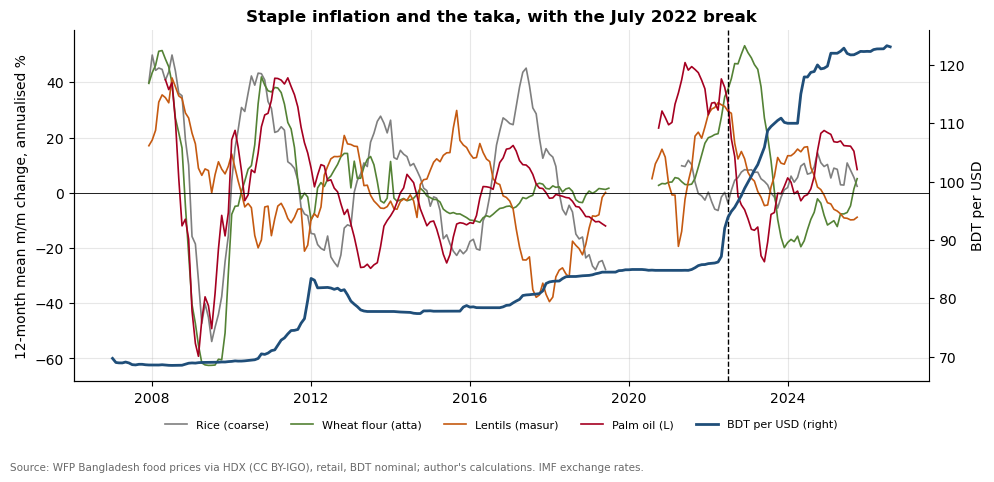

post2022_diff_rice_coarse: -0.12
post2022_diff_atta: -0.02
post2022_diff_lentil_masur: -0.25
post2022_diff_palm_oil: -0.57
post2022_diff_fisher_index: -0.28
post2022_diff_bdt_per_usd: 0.43
fx_pre_2022_06: 92.0
fx_latest: 123.1


In [16]:
fig, ax1 = plt.subplots(figsize=(10, 4.8))
roll = (mm[LONG].rolling(12).mean() * 12)
for it, col in zip(LONG, [GREY, GREEN, ORANGE, RED]):
    ax1.plot(roll.index, roll[it], color=col, lw=1.2, label=ITEM_LABEL[it])
ax1.axvline(brk, color="black", ls="--", lw=1)
ax1.axhline(0, color="black", lw=0.6)
ax1.set_ylabel("12-month mean m/m change, annualised %")
ax2 = ax1.twinx(); ax2.spines["right"].set_visible(True); ax2.grid(False)
ax2.plot(cov.loc["2007":].index, cov.loc["2007":].bdt_per_usd, color=BLUE, lw=2, label="BDT per USD (right)")
ax2.set_ylabel("BDT per USD")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.08), fontsize=8, ncol=5, frameon=False)
ax1.set_title("Staple inflation and the taka, with the July 2022 break")
save(fig, "fig12_before_after_2022", note=SRC_WFP + " IMF exchange rates.")
plt.show()
for _, r in pp.iterrows():
    fact(f"post2022_diff_{r['series']}", round(r.mean_post - r.mean_pre, 2), f"Post minus pre mean monthly change, pp (Newey-West p = {r.p_hac:.3f})")
fact("fx_pre_2022_06", round(cov.loc["2022-06-01", "bdt_per_usd"], 1), "BDT per USD, Jun 2022")
fact("fx_latest", round(cov.bdt_per_usd.dropna().iloc[-1], 1), f"BDT per USD, {str(cov.bdt_per_usd.dropna().index[-1].date())[:7]}")

### 5b. Is staple inflation more volatile than official food inflation?

Notebook 01 found that the SD of y/y inflation of the four-staple index is about 19 pp against under 3 pp for the official food CPI. A formal test:

- H0: the two variances are equal. H1: the staple index variance is larger.

The F-test for two variances is very sensitive to non-normality, so the Brown-Forsythe version of Levene's test (median-centred) is used as well. Both treat months as independent, which they are not, so a block bootstrap of the SD ratio (24-month blocks, both series resampled with the same blocks) gives the interval.

In [17]:
v = fis[["fisher_yoy", "cpi_food_2016_yoy"]].dropna()
a, b = v.fisher_yoy.values, v.cpi_food_2016_yoy.values
Fv = a.var(ddof=1) / b.var(ddof=1)
pF = stats.f.sf(Fv, len(a) - 1, len(b) - 1)
lev = stats.levene(a, b, center="median")
rng = np.random.default_rng(ts.RNG_SEED); n = len(a); L = 24; k = int(np.ceil(n / L))
idx = (rng.integers(0, n - L + 1, (4000, k))[:, :, None] + np.arange(L)).reshape(4000, -1)[:, :n]
ratio = a[idx].std(axis=1, ddof=1) / b[idx].std(axis=1, ddof=1)
lo, hi = np.quantile(ratio, [0.025, 0.975])
sec = "5b Variance"
R += [ts.row(sec, "F-test, one-sided", "staple Fisher y/y vs food CPI y/y", n, Fv, f"{n-1}, {n-1}", pF, "SD ratio", np.sqrt(Fv), (lo, hi), "CI from paired block bootstrap (24 m)"),
      ts.row(sec, "Brown-Forsythe (Levene, median)", "staple Fisher y/y vs food CPI y/y", n, lev.statistic, f"1, {2*n-2}", lev.pvalue, "SD ratio", np.sqrt(Fv), (lo, hi),
             "staple index far more volatile" if lev.pvalue < 0.05 else "no evidence")]
fact("sd_ratio_staples_vs_cpi", round(np.sqrt(Fv), 2), "SD of staple y/y over SD of food CPI y/y")
fact("sd_ratio_block_ci", f"{lo:.1f} to {hi:.1f}", "95% block bootstrap CI")
print(f"SD ratio {np.sqrt(Fv):.2f}, block-bootstrap CI {lo:.2f} to {hi:.2f}; F p = {pF:.2g}; Brown-Forsythe p = {lev.pvalue:.2g}")

sd_ratio_staples_vs_cpi: 6.93
sd_ratio_block_ci: 4.4 to 10.8
SD ratio 6.93, block-bootstrap CI 4.43 to 10.76; F p = 1.4e-123; Brown-Forsythe p = 5.9e-43


## 6. Many tests at once

This notebook runs well over a hundred tests. At the 5% level, about one in twenty true null hypotheses is rejected by chance, so some 'significant' results are expected even if nothing is going on. The Holm correction controls the chance of any false rejection within a family of tests. It orders the p-values and compares the smallest with 0.05/m, the next with 0.05/(m-1), and so on, which makes it never less powerful than Bonferroni. Here a family is one section of the notebook. The table below counts rejections before and after the correction.

In [18]:
res = ts.holm(pd.DataFrame(R), family="section")
res["reject_5pct"] = res.p < 0.05
res["reject_holm"] = res.p_holm < 0.05
res.to_csv(TAB / "tests_02_hypothesis.csv", index=False)
summ = res.groupby("section").agg(tests=("p", "count"), reject_raw=("reject_5pct", "sum"), reject_holm=("reject_holm", "sum"))
fact("tests_02_total", int(res.p.notna().sum()), "Tests with a p-value in notebook 02")
fact("tests_02_reject_raw", int(res.reject_5pct.sum()), "p < 0.05 before correction")
fact("tests_02_reject_holm", int(res.reject_holm.sum()), "p < 0.05 after Holm within section")
summ

tests_02_total: 152
tests_02_reject_raw: 70
tests_02_reject_holm: 66


,tests,reject_raw,reject_holm
section,,,
2 Dhaka vs division,60,50,49
3 Ramadan,12,0,0
3 Ramadan (2024-26 markets),14,0,0
3 Ramadan (regression),8,0,0
4 Divisions: annual inflation,16,0,0
4 Divisions: price level relative to national,16,14,14
5 Before/after Jul 2022,24,4,1
5b Variance,2,2,2


In [19]:
ts.write_facts(facts, "02")
res[["section", "test", "data", "statistic", "p", "p_holm", "effect_name", "effect", "ci_low", "ci_high"]].round(4).head(30)

,section,test,data,statistic,p,p_holm,effect_name,effect,ci_low,ci_high
0,2 Dhaka vs division,Paired t,rice_coarse: Dhaka - Barishal,-3.1763,0.0017,0.0222,Cohen's d_z,-0.2132,-1.9843,-0.4647
1,2 Dhaka vs division,Wilcoxon signed-rank,rice_coarse: Dhaka - Barishal,8650.0000,0.0008,0.0127,median gap %,-1.3088,NaN,NaN
2,2 Dhaka vs division,"Paired t, Newey-West SE",rice_coarse: Dhaka - Barishal,-1.9842,0.0472,0.5195,mean gap %,-1.2245,-2.4340,-0.0150
3,2 Dhaka vs division,Paired t,rice_coarse: Dhaka - Chattogram,-0.9307,0.3530,1.0000,Cohen's d_z,-0.0605,-1.3057,0.4678
4,2 Dhaka vs division,Wilcoxon signed-rank,rice_coarse: Dhaka - Chattogram,12882.0000,0.6118,1.0000,median gap %,0.0000,NaN,NaN
5,2 Dhaka vs division,"Paired t, Newey-West SE",rice_coarse: Dhaka - Chattogram,-0.5455,0.5854,1.0000,mean gap %,-0.4189,-1.9242,1.0864
6,2 Dhaka vs division,Paired t,rice_coarse: Dhaka - Khulna,11.7856,0.0000,0.0000,Cohen's d_z,0.7857,2.7160,3.8067
7,2 Dhaka vs division,Wilcoxon signed-rank,rice_coarse: Dhaka - Khulna,2237.0000,0.0000,0.0000,median gap %,3.2088,NaN,NaN
8,2 Dhaka vs division,"Paired t, Newey-West SE",rice_coarse: Dhaka - Khulna,7.8750,0.0000,0.0000,mean gap %,3.2613,2.4497,4.0730
9,2 Dhaka vs division,Paired t,rice_coarse: Dhaka - Rajshahi,19.6539,0.0000,0.0000,Cohen's d_z,1.2988,4.7424,5.7993


## What the tests say

Numbers below come from `tests_02_hypothesis.csv` and `key_facts_tests.csv` for this run.

- **Intervals.** Across markets in a single month the mean price is pinned down well: the median 95% half-width is about 1.6% of the mean, and the t and bootstrap limits agree to within 0.6%. Mean y/y inflation over 2007 to 2026 is a different matter. The naive t-interval for rice is 3.0% to 8.7%. Once the overlap between months is allowed for (Newey-West), it is -1.6% to 13.3%, between two and a half and three times wider, and it includes zero for all four staples. Twenty years of monthly data hold only a handful of independent inflation episodes.
- **Dhaka vs other divisions.** In 15 of 20 item-division pairs the gap is significant after Newey-West errors and Holm. The gaps are small, at most 7%, and they run both ways. Dhaka is cheaper than every other division for wheat flour and dearer than Rajshahi and Khulna for lentils and palm oil. So there is no general "Dhaka premium".
- **Ramadan.** Prices are not higher in the Ramadan month than in the two months before. For lentils, the 20-year drift-adjusted difference is +0.5% (one-sided p = 0.25), and palm oil, rice and wheat flour are slightly negative. In the 2025 and 2026 market data, sugar, onion, soybean oil and eggs were 2% to 7% cheaper in March than in January and February. The regression points the same way. The month before Ramadan carries a +1.9 pp coefficient for lentils (p = 0.09), and the Ramadan month itself carries nothing. Any rise comes before the fast, when households stock up, and it is not significant at 5%.
- **Divisions.** Price levels relative to the national average differ by division for all four staples (Welch ANOVA p < 0.001; eta squared 0.30 for rice to 0.68 for palm oil), and Tukey HSD finds 36 pairs that differ. Annual inflation does not differ at all (eta squared 0.002 or less, every p > 0.99). Divisions have different, stable price levels and share the same inflation, which fits one national market with fixed transport and trading margins.
- **Before and after mid-2022.** Mean monthly inflation of the staples and of the Fisher index was no higher after July 2022 than over 2007 to mid-2022 (all p > 0.4). The 2007-08 and 2010-11 food price spikes are in the "before" period, which explains part of this. The taka depreciated faster after the break: +0.43 pp per month, Newey-West p = 0.018, though not after Holm across the section.
- **Volatility.** The staple index's y/y inflation has 6.9 times the SD of official food CPI inflation (block-bootstrap CI 4.4 to 10.8). Four volatile staples are much noisier than a CPI basket of hundreds of items.
- **Multiple testing.** 70 of 152 p-values are below 0.05, and 66 stay below after Holm within each section. The results that survive are the Dhaka gaps, the division level differences and the variance ratio. The borderline ones (palm oil's Ramadan coefficient p = 0.06, the taka's post-2022 change in the Newey-West test) do not.